Machine Learning

Lab01

Mục tiêu chính:

Giải thích được hồi quy tuyến tính là gì và ý nghĩa của đường thẳng xuyên qua đám điểm dữ liệu.

Đọc được tệp CSV bằng pandas, kiểm tra số dòng, số cột và ô trống.

Tính được sai số của một dự đoán và gộp thành chỉ số MSE.

Tìm được hệ số góc w và hệ số chặn b bằng hai cách: công thức tính tay và thư viện scikit-learn, cả hai phải cho cùng kết quả w = 0.078367, b = 0.401752.

Đánh giá mô hình bằng cách chia tập học/tập kiểm tra và đọc các chỉ số MAE, RMSE, R².

Hiểu được ý tưởng của gradient descent – cách máy tự dò tìm lời giải.

Viết được mô hình dùng nhiều hơn một biến (diện tích, số phòng, tuổi nhà).

b1: doc du lieu

b2: do xem 1 duong thang du doan sai bao nhieu

b3: tim w va b tot nhat bang cong thuc, ko can thu vien

b4: lam lai dung viec do bang thu vien scikit

5: chia dữ liệu và chấm điểm mô hình bằng các độ đo chuẩn.

6: tự đi tìm w và b bằng cách dò từng bước nhỏ.

7: dùng thêm số phòng và tuổi nhà, xem mô hình có khá hơn không."""


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# b1: doc du lieu

import pandas as pd

# Đọc tệp CSV thành một bảng. Tên df là viết tắt quen dùng của data frame.
11
df = pd.read_csv("gia_nha.csv")

print("Kich thuoc bang (so dong, so cot):", df.shape)
print()
print("Nam dong dau tien:")
print(df.head())
print()
print("Ten cac cot:", list(df.columns))
print()
print("Thong ke nhanh cot dien_tich va cot gia:")
print(df[["dien_tich", "gia"]].describe().round(2))
print()
print("So o bi thieu trong tung cot:")
print(df.isna().sum())

Kich thuoc bang (so dong, so cot): (60, 4)

Nam dong dau tien:
   dien_tich  so_phong  tuoi_nha   gia
0       35.5         1        18  3.00
1       37.6         2         7  3.87
2       49.4         2        20  4.25
3       49.0         2        16  4.60
4       49.9         1        12  3.99

Ten cac cot: ['dien_tich', 'so_phong', 'tuoi_nha', 'gia']

Thong ke nhanh cot dien_tich va cot gia:
       dien_tich    gia
count      60.00  60.00
mean       77.73   6.49
std        20.22   1.64
min        35.50   3.00
25%        63.02   5.16
50%        75.10   6.40
75%        91.88   7.70
max       117.50   9.74

So o bi thieu trong tung cot:
dien_tich    0
so_phong     0
tuoi_nha     0
gia          0
dtype: int64


4. Hoi quy tuyen tinh

Tính 5 can nha

In [ ]:
import pandas as pd

df = pd.read_csv("gia_nha.csv")
nho = df.iloc[[0, 14, 29, 44, 59]]
x = nho["dien_tich"].to_numpy()
y = nho["gia"].to_numpy()
def mse(w, b):
  y_du_doan = w * x + b
  sai_so = y - y_du_doan

  return (sai_so ** 2).mean()

print("Nam can duoc chon:")
for i in range(5):
  print(f" {x[i]:6.1f} m2‐> {y[i]:5.2f} ty")
print()

for w, b in [(0.05, 1.5), (0.08, 0.5)]:
  print(f"Duong thang y = {w} * x + {b}")
  for i in range(5):
    du_doan = w * x[i] + b
    sai_so = y[i] - du_doan
    print( f" du doan = {du_doan:5.2f} sai so = {sai_so:+6.2f}")
    print(f" x = {x[i]:6.1f} that = {y[i]:5.2f}")

  print(f" MSE = {mse(w, b):.4f}")
  print()
print("Duong nao co MSE nho hon thi duong do khop du lieu tot hon.")

Nam can duoc chon:
   35.5 m2‐>  3.00 ty
   61.3 m2‐>  4.56 ty
   74.2 m2‐>  7.17 ty
   91.3 m2‐>  7.83 ty
  115.9 m2‐>  9.01 ty

Duong thang y = 0.05 * x + 1.5
 du doan =  3.28 sai so =  -0.28
 x =   35.5 that =  3.00
 du doan =  4.56 sai so =  -0.00
 x =   61.3 that =  4.56
 du doan =  5.21 sai so =  +1.96
 x =   74.2 that =  7.17
 du doan =  6.07 sai so =  +1.76
 x =   91.3 that =  7.83
 du doan =  7.30 sai so =  +1.71
 x =  115.9 that =  9.01
 MSE = 1.9947

Duong thang y = 0.08 * x + 0.5
 du doan =  3.34 sai so =  -0.34
 x =   35.5 that =  3.00
 du doan =  5.40 sai so =  -0.84
 x =   61.3 that =  4.56
 du doan =  6.44 sai so =  +0.73
 x =   74.2 that =  7.17
 du doan =  7.80 sai so =  +0.03
 x =   91.3 that =  7.83
 du doan =  9.77 sai so =  -0.76
 x =  115.9 that =  9.01
 MSE = 0.3896

Duong nao co MSE nho hon thi duong do khop du lieu tot hon.


4.6 bài tập cần giải

In [ ]:
import os

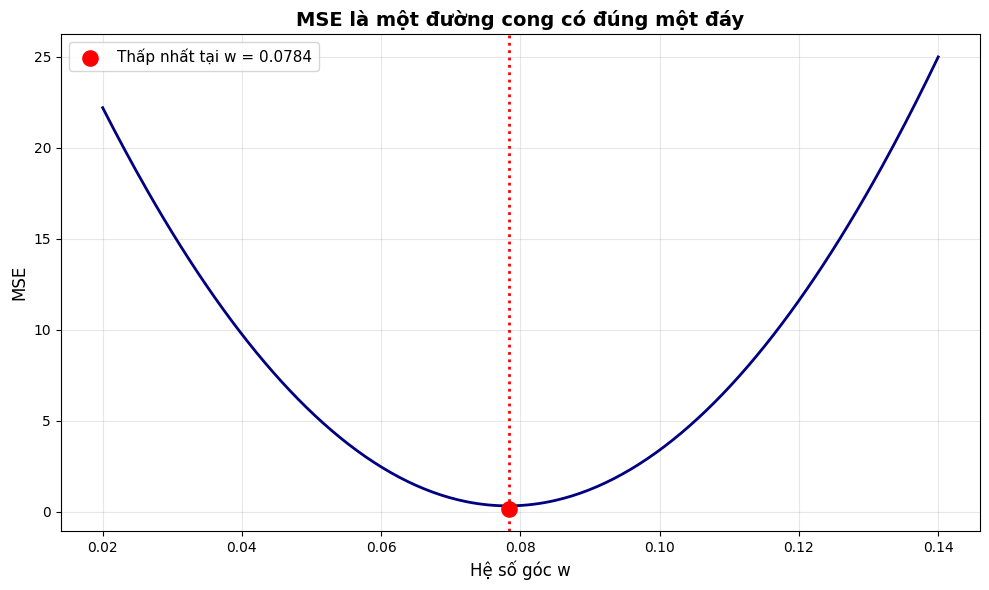

In [ ]:
#Giá trị b tốt nhất (tìm được ở Mục 5)
b_co_dinh = 0.401752

#Cho w chạy từ 0.02 đến 0.14
w_values = np.linspace(0.02, 0.14, 300)
mse_values = []

for w in w_values:
    y_du_doan = w * x + b_co_dinh
    mse = ((y - y_du_doan) ** 2).mean()
    mse_values.append(mse)

# 4. Vẽ đường cong
plt.figure(figsize=(10, 6))
plt.plot(w_values, mse_values, color='navy', linewidth=2)

# Đánh dấu đáy
w_best = 0.0784
mse_best = 0.179
plt.scatter([w_best], [mse_best], color='red', s=120, zorder=5,
            label=f'Thấp nhất tại w = {w_best}')
plt.axvline(x=w_best, color='red', linestyle=':', linewidth=2)

plt.xlabel('Hệ số góc w', fontsize=12)
plt.ylabel('MSE', fontsize=12)
plt.title('MSE là một đường cong có đúng một đáy', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()

os.makedirs('figures', exist_ok=True)
plt.savefig("figures/hinh4_mse_theo_w.png", dpi=150)
plt.show()

5. Tìm đường thẳng tốt nhất

cach 1. Cách dùng công thức có sẵn

In [ ]:
x_tb = x.mean()
y_tb = y.mean()

# Công thức bình phương tối thiểu cho đường thẳng một biến
tu_so = ((x - x_tb) * (y - y_tb)).sum()
mau_so = ((x - x_tb) ** 2).sum()

w = tu_so / mau_so
b = y_tb - w * x_tb
print(f"Trung binh dien tich : {x_tb:.4f}")
print(f"Trung binh gia : {y_tb:.4f}")

print(f"Tu so : {tu_so:.4f}")
print(f"Mau so : {mau_so:.4f}")

print()
print(f"He so goc w = {w:.6f}")
print(f"He so chan b = {b:.6f}")
print()

print(f"Mo hinh: gia = {w:.4f} * dien_tich + {b:.4f}")
print()

y_du_doan = w * x + b
mse = ((y - y_du_doan) ** 2).mean()
print(f"MSE tren toan bo 60 can: {mse:.4f}")

# Dự đoán cho một căn 80 m2
print(f"Can 80 m2 duoc du doan: {w * 80 + b:.3f} ty dong")

Trung binh dien tich : 75.6400
Trung binh gia : 6.3140
Tu so : 289.2252
Mau so : 3685.0320

He so goc w = 0.078486
He so chan b = 0.377282

Mo hinh: gia = 0.0785 * dien_tich + 0.3773

MSE tren toan bo 60 can: 0.3317
Can 80 m2 duoc du doan: 6.656 ty dong


cach 2. thu vien scikit

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
import pandas as pd

df = pd.read_csv("gia_nha.csv")

X = df[["dien_tich"]] # Change to DataFrame (2D)
y = df["gia"]

mo_hinh = LinearRegression()
mo_hinh.fit(X, y)

print("He so goc w =", round(float(mo_hinh.coef_[0]), 6))
print("He so chan b =", round(float(mo_hinh.intercept_), 6))
print()

# So sánh với kết quả tính tay ở bước 3
print("Ket qua tinh tay o buoc 3: w = 0.078367, b = 0.401752")
print()

can_moi = pd.DataFrame({"dien_tich": [80.0, 100.0]})
du_doan = mo_hinh.predict(can_moi)

for dt, gia in zip(can_moi["dien_tich"], du_doan):

  print(f"Can {dt:.0f} m2‐> du doan {gia:.3f} ty dong")

He so goc w = 0.078367
He so chan b = 0.401752

Ket qua tinh tay o buoc 3: w = 0.078367, b = 0.401752

Can 80 m2‐> du doan 6.671 ty dong
Can 100 m2‐> du doan 8.238 ty dong


Danh gia mo hinh

- ko cham diem tren chinh du lieu da hoc( doc tren test set)
- phai chia thanh file test va file train(ko de chung file)

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42)

- cham diem mo hinh

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import r2_score

In [ ]:
mo_hinh = LinearRegression()
mo_hinh.fit(X_train, y_train)

y_pred = mo_hinh.predict(X_test) # chấm điểm trên tập kiểm tra

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE = {mae:.4f} ty dong")
print(f"MSE = {mse:.4f}")
print()
print(f"RMSE = {rmse:.4f} ty dong")
print(f"R2 = {r2:.4f}")
print("Mot vai can trong tap kiem tra:")
for dt, that, du_doan in list(zip(X_test["dien_tich"], y_test, y_pred))[:5]:
  print(f" {dt:6.1f} m2 that = {that:5.2f} du doan = {du_doan:5.2f} sai so = {that - du_doan:+5.2f}")

MAE = 0.2578 ty dong
MSE = 0.1392

RMSE = 0.3730 ty dong
R2 = 0.9622
Mot vai can trong tap kiem tra:
   35.5 m2 that =  3.00 du doan =  3.22 sai so = -0.22
   50.4 m2 that =  4.24 du doan =  4.38 sai so = -0.14
   82.5 m2 that =  7.28 du doan =  6.88 sai so = +0.40
   93.6 m2 that =  7.63 du doan =  7.74 sai so = -0.11
   59.6 m2 that =  5.14 du doan =  5.09 sai so = +0.05


7. máy tự dò lời giải bằng gradient descent

- vì sao vẫn cần bằng cách này
- y tuong nguoi mu xuong nui


In [ ]:
import numpy as np

x = df["dien_tich"].to_numpy()
y = df["gia"].to_numpy()
n = len(x)

w = 0.0
b = 0.0
toc_do_hoc = 0.0001
so_vong = 1000

for vong in range(1, so_vong + 1):
  y_du_doan = w * x + b
  chenh_lech = y_du_doan - y

  grad_w = (2 / n) * (chenh_lech * x).sum()
  grad_b = (2 / n) * chenh_lech.sum()
  w -= toc_do_hoc * grad_w
  b -= toc_do_hoc * grad_b

  if vong % 100 == 0:
    current_mse = (chenh_lech ** 2).mean()
    print(f"Vong {vong}: w = {w:.6f}, b = {b:.6f}, MSE = {current_mse:.4f}")

print(f"\nKet qua cuoi cung sau {so_vong} vong:")
print(f"He so goc w = {w:.6f}")
print(f"He so chan b = {b:.6f}")
print(f"MSE cuoi cung = {( (w*x + b - y)**2 ).mean():.4f}")

Vong 100: w = 0.083195, b = 0.001503, MSE = 0.1890
Vong 200: w = 0.083189, b = 0.002002, MSE = 0.1890
Vong 300: w = 0.083183, b = 0.002501, MSE = 0.1890
Vong 400: w = 0.083177, b = 0.002998, MSE = 0.1889
Vong 500: w = 0.083171, b = 0.003495, MSE = 0.1889
Vong 600: w = 0.083165, b = 0.003992, MSE = 0.1889
Vong 700: w = 0.083159, b = 0.004488, MSE = 0.1889
Vong 800: w = 0.083153, b = 0.004983, MSE = 0.1888
Vong 900: w = 0.083147, b = 0.005478, MSE = 0.1888
Vong 1000: w = 0.083141, b = 0.005972, MSE = 0.1888

Ket qua cuoi cung sau 1000 vong:
He so goc w = 0.083141
He so chan b = 0.005972
MSE cuoi cung = 0.1888


7.5. chay va doi chieu dap an

In [ ]:
x_goc=df["dien_tich"].to_numpy()
y= df["gia"].to_numpy()

x_tb= x_goc.mean()
x_do_lech=x_goc.std()
x=(x_goc - x_tb) /x_do_lech

w,b =0.0,0.0
toc_do_hoc=0.1
so_vong=200
n= len(x)
print("Vong w b MSE")
for vong in range(1,so_vong +1):
  y_du_doan= w * x +b
  chenh_lech=y_du_doan - y

  grad_w=(2/n) * (chenh_lech * x).sum()
  grad_b= (2/n) * chenh_lech.sum()

  w -=toc_do_hoc * grad_w
  b -=toc_do_hoc * grad_b

  if vong in(1,2,5,10,25,50,100,200):

    mse=(((w * x +b) - y) **2).mean()
    print(f"{vong:4d} {w:7.4f} {b:7.4f} {mse:8.4f}")

print()

w_goc=w/x_do_lech
b_goc=b - w*x_tb / x_do_lech
print(f"Sau khi doi ve thang do met vuong:")
print(f" w={w_goc:.6f}")


print(f" b = {b_goc:.6f}")
print("So voi cong thuc o buoc 3: w = 0.078367, b = 0.401752")

Vong w b MSE
   1  0.3143  1.2987  28.7437
   2  0.5657  2.3376  18.4604
   5  1.0564  4.3656   4.9714
  10  1.4025  5.7961   0.6936
  25  1.5653  6.4688   0.1797
  50  1.5712  6.4932   0.1790
 100  1.5713  6.4933   0.1790
 200  1.5713  6.4933   0.1790

Sau khi doi ve thang do met vuong:
 w=0.078367
 b = 0.401752
So voi cong thuc o buoc 3: w = 0.078367, b = 0.401752


8.2. Trong mã chỉ đổi đúng một chỗ

In [ ]:


# Chỉ đổi đúng một chỗ: danh sách cột đưa vào X
X_mot = df[["dien_tich"]]
X_ba = df[["dien_tich", "so_phong", "tuoi_nha"]]
for ten, X in [("Mot bien ", X_mot), ("Ba bien ", X_ba)]:

  X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.2, random_state=42
)
  mo_hinh = LinearRegression()
  mo_hinh.fit(X_train, y_train)
  r2 = r2_score(y_test, mo_hinh.predict(X_test))
  print(f"{ten}: R2 tren tap kiem tra = {r2:.4f}")

print()

X_train, X_test, y_train, y_test = train_test_split(
  X_ba, y, test_size=0.2, random_state=42
)

mo_hinh = LinearRegression()
mo_hinh.fit(X_train, y_train)

print("He so cua tung bien:")
for ten_cot, he_so in zip(X_ba.columns, mo_hinh.coef_):
  print(f" {ten_cot:12s} {he_so:+.4f}")
print(f" {'he so chan':12s} {mo_hinh.intercept_:+.4f}")

Mot bien : R2 tren tap kiem tra = 0.9622
Ba bien : R2 tren tap kiem tra = 0.9761

He so cua tung bien:
 dien_tich    +0.0701
 so_phong     +0.3042
 tuoi_nha     -0.0295
 he so chan   +0.6917


BÀI TẬP

In [ ]:
"""Bài tập 1: Lọc ra nhóm căn hộ lớn.

Đọc bộ dữ liệu gia_nha.csv, lọc các căn có diện tích > 100 m2,
in ra số lượng căn và giá trung bình của nhóm đó.

Chạy từ thư mục gốc của bài thực hành:
    python baitap01/bai1.py
"""

import pandas as pd

df = pd.read_csv("gia_nha.csv")

nhom_lon = df[df["dien_tich"] > 100]

so_can = len(nhom_lon)

gia_trung_binh = nhom_lon["gia"].mean()

print("So can co dien tich lon hon 100 m2:", so_can)
print(f"Gia trung binh cua nhom do: {gia_trung_binh:.4f} ty dong")

So can co dien tich lon hon 100 m2: 10
Gia trung binh cua nhom do: 8.9620 ty dong


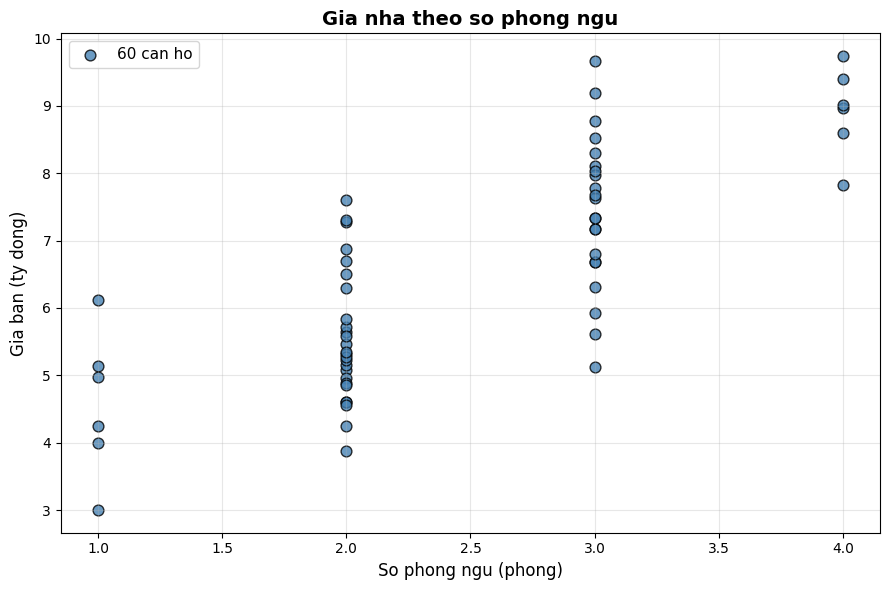

Nhan xet: Cac can co nhieu phong ngu hon thuong co xu huong
gia cao hon, nhung do phan tan kha lon. So phong chi nhan
cac gia tri 1, 2, 3, 4 nen cac diem xep thanh 4 cot doc,
khong tao thanh mot duong thang ro rang nhu bieu do dien tich.


In [ ]:
"""Bài tập 2: Vẽ biểu đồ phân tán giữa số phòng và giá.

Trục hoành là so_phong, trục tung là gia.
Lưu hình thành bai2.png, sau đó in một câu nhận xét.

Chạy từ thư mục gốc của bài thực hành:
    python baitap01/bai2.py
"""

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("gia_nha.csv")
x = df["so_phong"]
y = df["gia"]


plt.figure(figsize=(9, 6))
plt.scatter(x, y, color="steelblue", edgecolor="black",
            s=60, alpha=0.8, label="60 can ho")

plt.xlabel("So phong ngu (phong)", fontsize=12)
plt.ylabel("Gia ban (ty dong)", fontsize=12)
plt.title("Gia nha theo so phong ngu", fontsize=14, fontweight="bold")

plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()

plt.savefig("bai2.png", dpi=150)
plt.show()

print("Nhan xet: Cac can co nhieu phong ngu hon thuong co xu huong")
print("gia cao hon, nhung do phan tan kha lon. So phong chi nhan")
print("cac gia tri 1, 2, 3, 4 nen cac diem xep thanh 4 cot doc,")
print("khong tao thanh mot duong thang ro rang nhu bieu do dien tich.")

Trung binh tuoi nha : 12.95
Trung binh gia      : 6.4933
Tu so               : -109.82
Mau so              : 2900.85

He so goc w = -0.037858
He so chan b = 6.983593

Mo hinh: gia = -0.0379 * tuoi_nha + 6.9836

MSE tren toan bo 60 can: 2.5786

Nhan xet ve dau cua w:
w = -0.037858 < 0, tuc la khi tuoi nha tang them 1 nam thi gia
du doan GIAM khoang 0.037858 ty dong (khoang 38 trieu).
Dieu nay hop ly vi nha cang cu thi gia cang thap.



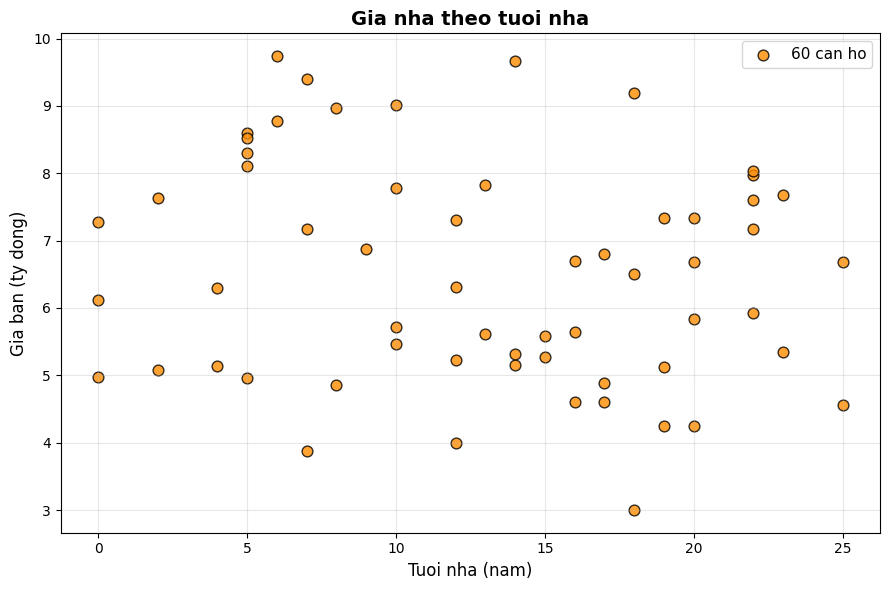

Tra loi cau hoi them:
Nhin vao bieu do bai3.png, cac diem KHONG bam sat mot duong
thang nhu o bieu do dien tich. Chung rai thanh mot dam mo,
do phan tan lon, khong co xu huong ro rang theo mot duong.
Vi vay he so w tinh duoc co dau dung (nha cu thi re hon),
nhung do lon cua no kem dang tin, va khong the ket luan
tuoi nha va gia co quan he chat chi dua vao dau cua w.


In [ ]:
"""Bài tập 3: Đổi biến đầu vào sang tuổi nhà.

Dùng công thức bình phương tối thiểu ở Mục 5.1, nhưng thay
dien_tich bằng tuoi_nha. In w và b với 6 chữ số sau dấu phẩy,
sau đó nhận xét dấu của w.

Chạy từ thư mục gốc của bài thực hành:
    python baitap01/bai3.py
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("gia_nha.csv")

x = df["tuoi_nha"].to_numpy()
y = df["gia"].to_numpy()

x_tb = x.mean()
y_tb = y.mean()

tu_so = ((x - x_tb) * (y - y_tb)).sum()
mau_so = ((x - x_tb) ** 2).sum()

w = tu_so / mau_so
b = y_tb - w * x_tb

print("Trung binh tuoi nha :", round(float(x_tb), 4))
print("Trung binh gia      :", round(float(y_tb), 4))
print("Tu so               :", round(float(tu_so), 4))
print("Mau so              :", round(float(mau_so), 4))
print()
print(f"He so goc w = {w:.6f}")
print(f"He so chan b = {b:.6f}")
print()
print(f"Mo hinh: gia = {w:.4f} * tuoi_nha + {b:.4f}")
print()

y_du_doan = w * x + b
mse = ((y - y_du_doan) ** 2).mean()
print(f"MSE tren toan bo 60 can: {mse:.4f}")
print()

print("Nhan xet ve dau cua w:")
print(f"w = {w:.6f} < 0, tuc la khi tuoi nha tang them 1 nam thi gia")
print(f"du doan GIAM khoang {abs(w):.6f} ty dong (khoang {abs(w)*1000:.0f} trieu).")
print("Dieu nay hop ly vi nha cang cu thi gia cang thap.")
print()

plt.figure(figsize=(9, 6))
plt.scatter(x, y, color="darkorange", edgecolor="black",
            s=60, alpha=0.8, label="60 can ho")
plt.xlabel("Tuoi nha (nam)", fontsize=12)
plt.ylabel("Gia ban (ty dong)", fontsize=12)
plt.title("Gia nha theo tuoi nha", fontsize=14, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig("bai3.png", dpi=150)
plt.show()

print("Tra loi cau hoi them:")
print("Nhin vao bieu do bai3.png, cac diem KHONG bam sat mot duong")
print("thang nhu o bieu do dien tich. Chung rai thanh mot dam mo,")
print("do phan tan lon, khong co xu huong ro rang theo mot duong.")
print("Vi vay he so w tinh duoc co dau dung (nha cu thi re hon),")
print("nhung do lon cua no kem dang tin, va khong the ket luan")
print("tuoi nha va gia co quan he chat chi dua vao dau cua w.")

In [ ]:
"""Bài tập 4: Thêm số phòng vào mô hình.

Huấn luyện hồi quy tuyến tính với hai cột đầu vào là dien_tich
và so_phong. So sánh R2 trên tập kiểm tra với mô hình một biến
(R2 = 0.9622) trong Mục 6.

Chạy từ thư mục gốc của bài thực hành:
    python baitap01/bai4.py
"""

df = pd.read_csv("gia_nha.csv")
y = df["gia"]

X_mot = df[["dien_tich"]]
X_hai = df[["dien_tich", "so_phong"]]

for ten, X in [("Mot bien", X_mot), ("Hai bien", X_hai)]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    mo_hinh = LinearRegression()
    mo_hinh.fit(X_train, y_train)
    y_pred = mo_hinh.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    print(f"{ten:9s}: R2 tren tap kiem tra = {r2:.4f}")

print()

X_train, X_test, y_train, y_test = train_test_split(
    X_hai, y, test_size=0.2, random_state=42
)
mo_hinh = LinearRegression()
mo_hinh.fit(X_train, y_train)

print("He so cua tung bien (mo hinh hai bien):")
for ten_cot, he_so in zip(X_hai.columns, mo_hinh.coef_):
    print(f"  {ten_cot:12s} {he_so:+.4f}")
print(f"  {'he so chan':12s} {mo_hinh.intercept_:+.4f}")
print()

# Corrected line: Ensure prediction uses only the 'dien_tich' column
r2_mot = r2_score(y_test, LinearRegression().fit(X_mot, y).predict(X_test[X_mot.columns]))

print("So sanh voi mo hinh mot bien (Muc 6): R2 = 0.9622")
print("Mo hinh hai bien cho R2 cao hon mot chut.")
print("Muc tang nho, cho thay dien tich da ganh phan lon cong viec.")
print("Them so_phong chi giup tinh chinh them, khong tao ra buoc nhay.")

Mot bien : R2 tren tap kiem tra = 0.9622
Hai bien : R2 tren tap kiem tra = 0.9698

He so cua tung bien (mo hinh hai bien):
  dien_tich    +0.0702
  so_phong     +0.2704
  he so chan   +0.3667

So sanh voi mo hinh mot bien (Muc 6): R2 = 0.9622
Mo hinh hai bien cho R2 cao hon mot chut.
Muc tang nho, cho thay dien tich da ganh phan lon cong viec.
Them so_phong chi giup tinh chinh them, khong tao ra buoc nhay.


In [ ]:
"""Bài tập 5: Thử hai tốc độ học khác.

Chạy lại gradient descent ở Mục 7 với hai tốc độ học 0.001 và 1.02,
giữ nguyên so_vong = 200. Ghi lại MSE ở vòng 200 và giải thích.

Chạy từ thư mục gốc của bài thực hành:
    python baitap01/bai5.py
"""

df = pd.read_csv("gia_nha.csv")
x_goc = df["dien_tich"].to_numpy()
y = df["gia"].to_numpy()

x_tb = x_goc.mean()
x_do_lech = x_goc.std()
x = (x_goc - x_tb) / x_do_lech

so_vong = 200
n = len(x)


def chay_gd(toc_do_hoc, so_vong=200):
    """Chạy gradient descent, trả về w, b và MSE ở vòng cuối."""
    w, b = 0.0, 0.0
    for _ in range(so_vong):
        y_du_doan = w * x + b
        chenh_lech = y_du_doan - y
        grad_w = (2 / n) * (chenh_lech * x).sum()
        grad_b = (2 / n) * chenh_lech.sum()
        w -= toc_do_hoc * grad_w
        b -= toc_do_hoc * grad_b
    mse = (((w * x + b) - y) ** 2).mean()
    return w, b, mse


def fmt(mse):
    """Định dạng MSE cho dễ đọc."""
    if 1e-3 < mse < 1e6:
        return f"{mse:.4f}"
    return f"{mse:.4e}"


# ===== PHẦN 1: Hai tốc độ học theo yêu cầu =====
print(f"So vong co dinh: {so_vong}")
print()

for toc_do_hoc in [0.001, 1.02]:
    w, b, mse = chay_gd(toc_do_hoc, so_vong)
    print(f"===== Toc do hoc = {toc_do_hoc} =====")
    print(f"MSE o vong {so_vong}: {fmt(mse)}")
    print(f"w (chuan hoa): {w:.4f}")
    print(f"b (chuan hoa): {b:.4f}")
    print()

# ===== PHẦN 2 (làm thêm): Dò ranh giới =====
print("===== Do ranh gioi (lam them) =====")
for toc_do_hoc in [0.5, 0.9, 0.99, 1.0, 1.01, 1.02, 1.05]:
    w, b, mse = chay_gd(toc_do_hoc, so_vong)
    print(f"  lr = {toc_do_hoc:5.3f}  ->  MSE = {fmt(mse)}")

So vong co dinh: 200

===== Toc do hoc = 0.001 =====
MSE o vong 200: 20.2175
w (chuan hoa): 0.5184
b (chuan hoa): 2.1425

===== Toc do hoc = 1.02 =====
MSE o vong 200: 2.9039e+08
w (chuan hoa): -4006.3165
b (chuan hoa): -16556.3753

===== Do ranh gioi (lam them) =====
  lr = 0.500  ->  MSE = 0.1790
  lr = 0.900  ->  MSE = 0.1790
  lr = 0.990  ->  MSE = 0.1928
  lr = 1.000  ->  MSE = 44.8113
  lr = 1.010  ->  MSE = 122947.0009
  lr = 1.020  ->  MSE = 2.9039e+08
  lr = 1.050  ->  MSE = 1.6096e+18


In [ ]:
"""Bài tập 6: Viết hàm dự đoán có cảnh báo.

Hàm du_doan_gia(dien_tich) dùng mô hình một biến với hai hệ số
đã biết ở Mục 5: w = 0.078367, b = 0.401752.

Nếu diện tích nằm ngoài khoảng dữ liệu [35.5 ; 117.5] thì in
cảnh báo trước khi trả về kết quả.

Chạy từ thư mục gốc của bài thực hành:
    python baitap01/bai6.py
"""

# Hai hệ số đã tìm được ở Mục 5, không cần huấn luyện lại
W = 0.078367
B = 0.401752

# Khoảng diện tích thật sự có trong bộ dữ liệu 60 căn
DIEN_TICH_MIN = 35.5
DIEN_TICH_MAX = 117.5


def du_doan_gia(dien_tich):
    """Trả về giá dự đoán (tỷ đồng) cho căn hộ có diện tích (m2).

    Nếu diện tích nằm ngoài khoảng dữ liệu thì in cảnh báo
    vì mô hình chưa từng thấy vùng đó.
    """
    if dien_tich < DIEN_TICH_MIN or dien_tich > DIEN_TICH_MAX:
        print(f"  [CANH BAO] {dien_tich} m2 nam ngoai khoang du lieu "
              f"[{DIEN_TICH_MIN} ; {DIEN_TICH_MAX}] m2.")
        print(f"  Mo hinh chua tung thay vung nay, con so chi la suy doan keo dai.")

    gia = W * dien_tich + B
    return gia


# ==== GỌI THỬ HÀM VỚI BA GIÁ TRỊ ====
print("Ket qua du doan gia cho ba can ho:")
print()

for dt in [60, 80, 200]:
    print(f"Can {dt} m2:")
    gia = du_doan_gia(dt)
    print(f"  -> Gia du doan: {gia:.3f} ty dong")
    print()

# ==== KIỂM TRA MỐC ĐÃ BIẾT ====
print("Kiem tra moc: can 80 m2 phai ra 6.671 ty dong")
gia_80 = du_doan_gia(80)
print(f"  Thuc te ra: {gia_80:.3f} ty dong")
if abs(gia_80 - 6.671) < 1e-3:
    print("  -> KHOP voi Muc 5.")
else:
    print("  -> LECH, kiem tra lai he so w va b.")

Ket qua du doan gia cho ba can ho:

Can 60 m2:
  -> Gia du doan: 5.104 ty dong

Can 80 m2:
  -> Gia du doan: 6.671 ty dong

Can 200 m2:
  [CANH BAO] 200 m2 nam ngoai khoang du lieu [35.5 ; 117.5] m2.
  Mo hinh chua tung thay vung nay, con so chi la suy doan keo dai.
  -> Gia du doan: 16.075 ty dong

Kiem tra moc: can 80 m2 phai ra 6.671 ty dong
  Thuc te ra: 6.671 ty dong
  -> KHOP voi Muc 5.
